Linear SVM Classification and Margin Visualization using the Iris Dataset

Step 1: Import Libraries and Load Dataset

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
# Load Iris dataset
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target_names[iris.target]
print(df.head())
print(df['species'].value_counts())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Step 2: Exploratory Data Analysis

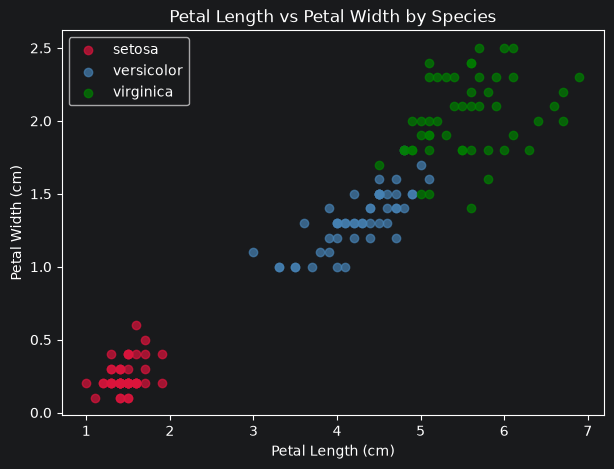

In [3]:
# Use two features for easy 2D visualization: petal length and petal width
plt.figure(figsize=(7, 5))
for species, color in zip(iris.target_names, ['crimson', 'steelblue', 'green']):
    subset = df[df['species'] == species]
    plt.scatter(subset['petal length (cm)'], subset['petal width (cm)'],label=species, alpha=0.7, color=color)
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('Petal Length vs Petal Width by Species')
plt.legend()
plt.show()

Step 3: Create Binary Labels and Select Features

In [4]:
# Binary target: Setosa (1) vs Non-Setosa (0)
y_binary = (iris.target == 0).astype(int)
# Use petal length and petal width — Setosa is linearly separable on these features
X = df[['petal length (cm)', 'petal width (cm)']].values

Step 4: Data Preprocessing

In [5]:
# Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
X, y_binary, test_size=0.2, random_state=42, stratify=y_binary)
# Feature scaling (important for SVM, which is distance/margin based)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Step 5: Train the Linear SVM

In [ ]:
svm_model = SVC(kernel='linear', C=1.0)
svm_model.fit(X_train_scaled, y_train)
y_pred = svm_model.predict(X_test_scaled)

Traceback (most recent call last):
  File "C:\Program Files\JetBrains\PyCharm 2026.1.2\plugins\python-ce\helpers\pydev\_pydevd_bundle\pydevd_comm.py", line 735, in make_thread_stack_str
    append('file="%s" line="%s">' % (make_valid_xml_value(my_file), lineno))
                                     ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^
  File "C:\Program Files\JetBrains\PyCharm 2026.1.2\plugins\python-ce\helpers\pydev\_pydevd_bundle\pydevd_xml.py", line 36, in make_valid_xml_value
    return s.replace("&", "&amp;").replace('<', '&lt;').replace('>', '&gt;').replace('"', '&quot;')
           ^^^^^^^^^
AttributeError: 'tuple' object has no attribute 'replace'


Step 6: Evaluate the Model

In [6]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print(f'Accuracy={acc:.4f} Precision={prec:.4f} Recall={rec:.4f} F1={f1:.4f}')
print('Confusion Matrix:')
print(cm)

Accuracy=1.0000 Precision=1.0000 Recall=1.0000 F1=1.0000
Confusion Matrix:
[[20  0]
 [ 0 10]]


Step 7: Visualize the Decision Boundary and Margin

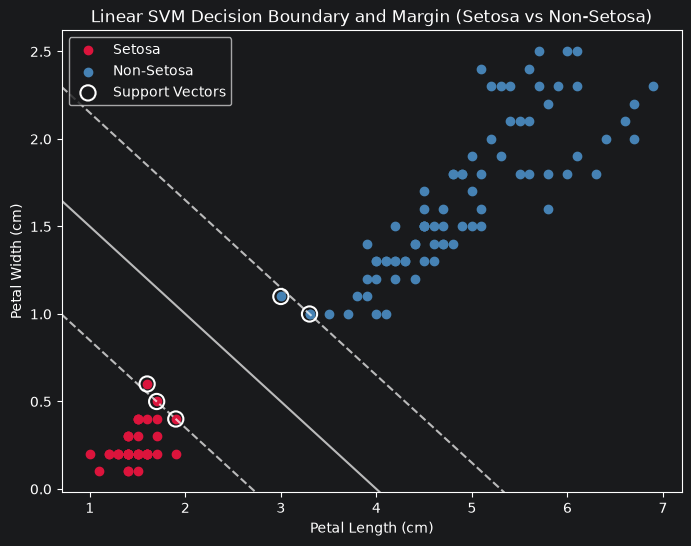

In [8]:
def plot_svm_boundary(model, X, y, scaler):
    X_orig = scaler.inverse_transform(X)
    plt.figure(figsize=(8, 6))
    plt.scatter(X_orig[y == 1, 0], X_orig[y == 1, 1], color='crimson', label='Setosa')
    plt.scatter(X_orig[y == 0, 0], X_orig[y == 0, 1], color='steelblue', label='Non-Setosa')
    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    xx = np.linspace(xlim[0], xlim[1], 200)
    yy = np.linspace(ylim[0], ylim[1], 200)
    YY, XX = np.meshgrid(yy, xx)
    xy_scaled = scaler.transform(np.c_[XX.ravel(), YY.ravel()])
    Z = model.decision_function(xy_scaled).reshape(XX.shape)
    # Decision boundary (0) and margins (+1, -1)
    ax.contour(XX, YY, Z, colors='white',levels=[-1, 0, 1], alpha=0.7,
    linestyles=['--', '-', '--'])
    # Highlight support vectors
    sv_orig = scaler.inverse_transform(model.support_vectors_)
    ax.scatter(sv_orig[:, 0], sv_orig[:, 1], s=120,
    facecolors='none', edgecolors='white', linewidths=1.5,
    label='Support Vectors')
    plt.xlabel('Petal Length (cm)')
    plt.ylabel('Petal Width (cm)')
    plt.title('Linear SVM Decision Boundary and Margin (Setosa vs Non-Setosa)')
    plt.legend()
    plt.show()
plot_svm_boundary(svm_model, X_train_scaled, y_train, scaler)